## Contexto

> Este TP2 toma como punto de partida directo lo realizado en el TP1: antes de detectar ofertas, primero hay que definir **qué observaciones son comparables** y con qué granularidad conviene agrupar el mercado.

En el TP1 se observó que la comparación por ciudad cruda era inestable por fragmentación de nombres y baja representatividad en muchos destinos. Por eso, en TP2 priorizamos tres decisiones metodológicas:
- retomar lo trabajado en la consolidación de destinos con `destination_with_nearest.csv` para construir `destination_final`;
- mantener la unidad temporal en **noche pagada** (checkout excluido);
- normalizar precios a `price_std` para comparar búsquedas con distinta duración y ocupación.

Con ese marco, el TP2 se enfoca en medir el trade-off entre soporte y homogeneidad para distintas definiciones de contexto (A, B, C), las cuale se presentarán a continuación, y dejar una recomendación argumentada para el diseño del TP3.

## Objetivo

El TP2 tiene dos partes. La primera es operativa: limpiar y estructurar los datos para que sean comparables. Esto implica normalizar el precio a una unidad común (`precio_total / (noches × habitaciones × personas)`), construir las features de contexto que definen el mercado según lo que mostró el TP1 (día de la semana, mes, categoría de hotel, etc.), y aplicar el mapping de `destination_with_nearest.csv` para consolidar los ~26.000 nombres de ciudad en identificadores únicos — o proponer una agrupación alternativa con evidencia que la soporte. Es también el momento de auditar la calidad de los datos: precios inválidos, noches inconsistentes, búsquedas con ocupación cero.

La segunda parte es analítica: con los datos ya segmentados en mercados, explorar cómo se distribuyen los precios dentro de cada uno. ¿Qué forma tiene esa distribución? ¿Hay precios que claramente se alejan del resto? ¿Qué estadístico distingue mejor los precios inusualmente bajos — percentiles, distancia a la media, otra cosa? Este análisis no tiene que llegar a un algoritmo final, pero sí a primeras observaciones concretas que orienten el diseño del TP3.

La decisión más importante del TP2 es la definición de mercado que el grupo va a usar. Vale documentarla y justificarla con evidencia — porque condiciona todo lo que viene después.

Entrega: dataset curado con features construidas, definición de mercado implementada, y análisis exploratorio de cómo se distribuyen los precios dentro de cada segmento.

## Estado actual del pipeline

- Unidad de análisis temporal: se definió correctamente por noche pagada (checkout excluido) y quedó validada con tests específicos.
- Demanda ponderada: count_repeated se usa como peso de demanda, y se explicita en cada métrica cuándo hay ponderación y cuándo no.
- Corrección de mapping: el flujo productivo mejoró de 0,0% a 28,1% de match en el rerun completo.
- Base de evidencia: las conclusiones de cierre ya no se apoyan en muestras pequeñas, sino en la corrida completa 2024+2025.
- Escenarios comparados: se evaluaron tres definiciones de mercado con métricas homogéneas: A (destino+mes), B (destino+mes+bucket), C (destino+mes+semana).
- Aprendizaje principal del trade-off: al aumentar segmentación mejora la homogeneidad, pero cae el soporte por contexto; no existe un ganador sin costo.
- Tratamiento de outliers: no se eliminan por defecto; se consideran señal potencial y se analizan en contexto.
- Estado del algoritmo final: TP2 no cierra un algoritmo definitivo; deja evidencia concreta para diseñar TP3 con fundamento.
- Decisión metodológica clave: la definición de mercado es la decisión más relevante porque condiciona baseline, sensibilidad y robustez posterior.

In [8]:
import pandas as pd
import numpy as np
from pathlib import Path
import sys

# Para importar funciones del repo cuando corrés desde notebook
ROOT = Path(".").resolve()
sys.path.insert(0, str(ROOT))

# Locate the module inside the project, including nested folders.
module_file = next(ROOT.rglob("auxiliary_functions.py"), None)

if module_file is None:
    search_roots = [ROOT, *ROOT.parents]

    for search_root in search_roots:
        module_file = next(
            search_root.rglob("auxiliary_functions.py"),
            None,
        )
        if module_file is not None:
            break

    if module_file is None:
        raise FileNotFoundError(
            "No se encontró auxiliary_functions.py en el notebook, "
            f"ni en sus carpetas padre: {ROOT}"
        )

sys.path.insert(0, str(module_file.parent))

import auxiliary_functions

MIN_OBS = 30

# =========================
# 1) A/B/C desde baselines
# =========================
# Buscar el archivo tanto en TP2 como en la carpeta raíz del proyecto
baseline_file = next(
    (
        p
        for base in [ROOT, *ROOT.parents]
        for p in [base / "outputs" / "market_baselines.csv"]
        if p.is_file()
    ),
    None,
)

if baseline_file is None:
    raise FileNotFoundError(
        "No se encontró market_baselines.csv en la carpeta del notebook "
        "ni en sus carpetas padre."
    )

b = pd.read_csv(baseline_file)

x = b[
    [
        "destination_final",
        "month",
        "week_in_month",
        "price_bucket",
        "mean_price_std",
        "std_price_std",
        "count_obs",
    ]
].copy()

for c in ["mean_price_std", "std_price_std", "count_obs"]:
    x[c] = pd.to_numeric(x[c], errors="coerce")

x = x.dropna(subset=["mean_price_std", "std_price_std", "count_obs"])


def combine(g):
    n = g["count_obs"].values.astype(float)
    m = g["mean_price_std"].values.astype(float)
    s = g["std_price_std"].values.astype(float)

    N = n.sum()
    mean = (n * m).sum() / N if N > 0 else np.nan

    if N <= 1:
        std = np.nan
    else:
        ssw = np.sum((n - 1) * np.square(s))
        ssb = np.sum(n * np.square(m - mean))
        std = np.sqrt(max((ssw + ssb) / (N - 1), 0.0))

    return pd.Series(
        {
            "count_obs": N,
            "mean_price_std": mean,
            "std_price_std": std,
        }
    )

A = x.groupby(["destination_final", "month"], dropna=False).apply(combine).reset_index()
B = x.groupby(["destination_final", "month", "price_bucket"], dropna=False).apply(combine).reset_index()
C = x.groupby(["destination_final", "month", "week_in_month"], dropna=False).apply(combine).reset_index()

def summarize(df_scn, label):
    r = df_scn["std_price_std"] / df_scn["mean_price_std"]
    return {
        "escenario": label,
        "median_count_obs": float(df_scn["count_obs"].median()),
        "median_std_over_mean": float(r.median()),
        "pct_contexts_ge30": float((df_scn["count_obs"] >= MIN_OBS).mean() * 100),
        "cv_mensual_mediano": np.nan,      # lo llenás aparte si querés con tu script
        "deal_pct_caida20": np.nan,        # idem
    }

df = pd.DataFrame(
    [
        summarize(A, "A"),
        summarize(B, "B"),
        summarize(C, "C"),
    ]
)

print(df)

# ==========================================
# 2) mapping_df sin hardcode (muestra controlada)
# ==========================================
def mapping_match_pct(uppercase_country: bool, sample_n: int = 120_000):
    d24 = pd.read_csv("data/datos_historicos_2024.csv", nrows=sample_n, low_memory=False)
    d25 = pd.read_csv("data/datos_historicos_2025.csv", nrows=sample_n, low_memory=False)
    d = pd.concat([d24, d25], ignore_index=True)

    if uppercase_country:
        d["country_code"] = d["country_code"].astype(str).str.upper()

    mapping_df_local = auxiliary_functions.load_destination_mapping()
    mapped = auxiliary_functions.apply_destination_mapping(d.copy(), mapping_df_local)
    return float(mapped["nearest_destination_id"].notna().mean() * 100)

# Buscar los datos desde la carpeta del proyecto, no desde el cwd del notebook
data_dir = next(
    (
        base / "data"
        for base in [ROOT, *ROOT.parents]
        if (base / "data" / "datos_historicos_2024.csv").is_file()
        and (base / "data" / "datos_historicos_2025.csv").is_file()
    ),
    None,
)

if data_dir is None:
    raise FileNotFoundError(
        "No se encontraron los archivos históricos en ninguna carpeta data."
    )


def mapping_match_pct(uppercase_country: bool, sample_n: int = 120_000):
    d24 = pd.read_csv(
        data_dir / "datos_historicos_2024.csv",
        nrows=sample_n,
        low_memory=False,
    )
    d25 = pd.read_csv(
        data_dir / "datos_historicos_2025.csv",
        nrows=sample_n,
        low_memory=False,
    )

    d = pd.concat([d24, d25], ignore_index=True)

    if uppercase_country:
        d["country_code"] = d["country_code"].astype(str).str.upper()

    mapping_df_local = auxiliary_functions.load_destination_mapping()
    mapped = auxiliary_functions.apply_destination_mapping(
        d.copy(), mapping_df_local
    )

    return float(mapped["nearest_destination_id"].notna().mean() * 100)


mapping_df = pd.DataFrame(
    [
        {
            "estado": "Antes fix (simulado)",
            "match_pct": mapping_match_pct(uppercase_country=False),
        },
        {
            "estado": "Despues fix (simulado)",
            "match_pct": mapping_match_pct(uppercase_country=True),
        },
    ]
)

print(mapping_df)


  escenario  median_count_obs  median_std_over_mean  pct_contexts_ge30  \
0         A              14.0              0.207071          36.202394   
1         B              10.0              0.100987          29.377626   
2         C               9.0              0.157237          27.147568   

   cv_mensual_mediano  deal_pct_caida20  
0                 NaN               NaN  
1                 NaN               NaN  
2                 NaN               NaN  


2026-09-04 21:11:22,113 - INFO - Mapping cargado: 15,988 registros
2026-09-04 21:11:22,516 - INFO - Mapping aplicado: 87,199/240,000 registros (36.3%)
2026-09-04 21:11:22,525 - INFO - Destinos únicos: 1,631
2026-09-04 21:11:22,941 - INFO - Mapping cargado: 15,988 registros
2026-09-04 21:11:23,191 - INFO - Mapping aplicado: 87,199/240,000 registros (36.3%)
2026-09-04 21:11:23,199 - INFO - Destinos únicos: 1,631


                   estado  match_pct
0    Antes fix (simulado)  36.332917
1  Despues fix (simulado)  36.332917


## Matriz de decisión

### Interpretación de la comparación de escenarios

> Escenarios evaluados
- **A:** `destination_final × month`
- **B:** `destination_final × month × price_bucket`
- **C:** `destination_final × month × week_in_month`

> Criterios evaluados
- soporte
- cobertura
- estabilidad temporal
- sensibilidad
- dispersión

> Cómo se obtienen los datos de esta matriz (paso a paso)
1. Se ejecuta `scripts/check_mapping_case.py` para validar impacto de normalizar `country_code` (control de match).
2. Se corre `pipeline_build_baselines.py`, que usa funciones de `auxiliary_functions.py` (validación, mapping, expansión temporal, estandarización y cálculo de baselines).
3. El pipeline genera `outputs/market_baselines.csv`, base única para recomputar escenarios A/B/C.
4. Se ejecuta `scripts/check_baselines.py` para resumir soporte y dispersión por escenario.
5. Se ejecuta `scripts/fill_matrix_metrics.py` para calcular cobertura, estabilidad (CV mensual) y sensibilidad (% Deal con caída controlada).
6. Los valores finales se integran en esta sección y se contrastan con gráficos de soporte.

### Soporte

> Justificación 

El soporte mide cuánta evidencia empírica tiene cada contexto para sostener inferencias estables. Si un contexto tiene pocas observaciones, el baseline depende demasiado de ruido puntual y la clasificación de ofertas se vuelve frágil. Por eso no alcanza con mirar promedio o mediana de precio: también importa la densidad de datos detrás de esa referencia. En este TP usamos como umbral operativo `count_obs >= 30` para distinguir contextos utilizables sin fallback inmediato. A mayor granularidad (más dimensiones), el soporte cae porque el histórico se reparte en más celdas. Esta métrica hace explícito ese costo metodológico.

| Escenario | Contextos | Mediana obs | % contextos ≥30 |
|------------|-----------:|------------:|----------------:|
| A | 173.483 | 14 | 36,2% |
| B | 340.824 | 10 | 29,4% |
| C | 437.914 | 9 | 27,1% |

> Nota: A conserva más soporte por contexto; C es el más fragmentado.

---

### Cobertura

> Justificación  

La cobertura responde una pregunta complementaria al soporte: no cuántos contextos son robustos, sino qué proporción del volumen total de observaciones queda efectivamente representada por contextos robustos. Esta distinción es clave porque un porcentaje moderado de contextos puede concentrar gran parte de la demanda ponderada. En términos operativos, permite saber si la estrategia elegida sirve para la mayor parte del tráfico aunque queden bordes de baja densidad. En TP2 observamos coberturas altas en los tres escenarios, aun cuando cae el soporte por celda. Por eso cobertura y soporte deben interpretarse juntas, no por separado.

| Escenario | Cobertura observacional (obs en contextos ≥30) |
|------------|-----------------------------------------------:|
| A | 99,02% |
| B | 98,01% |
| C | 97,51% |

> Nota: la segmentación extra reduce soporte puntual, pero mantiene cobertura global alta.

---

### Estabilidad temporal

> Justificación 

La estabilidad temporal evalúa si el baseline cambia de forma brusca entre meses para un mismo criterio de segmentación. Usamos el coeficiente de variación mensual (CV) de `mean_price_std`, porque permite comparar volatilidad relativa entre escenarios con escalas distintas. Un CV menor implica referencia más predecible y menor riesgo de sobre-reaccionar a oscilaciones transitorias. Esta métrica es especialmente útil para producción, donde se necesita consistencia para etiquetar precios día a día. En nuestros resultados, B logra mejor estabilidad al controlar heterogeneidad por bucket. Eso sugiere una señal más estructurada para el TP3.

| Escenario | CV mensual mediano |
|------------|-------------------:|
| A | 0,3250 |
| B | 0,1578 |
| C | 0,3384 |

> Nota: B es el más estable en el tiempo.

---

### Sensibilidad

> Justificación  

La sensibilidad mide capacidad de reacción del sistema frente a una mejora real de precio. En lugar de asumirla teóricamente, la medimos con un experimento controlado: caída del 20% y recálculo de clasificación. Si el porcentaje de casos que pasan a "Deal" sube de forma consistente, el escenario captura mejor oportunidades relevantes para negocio. Pero sensibilidad alta sin soporte suficiente puede producir falsos positivos en contextos débiles; por eso se interpreta junto al riesgo de fallback. En TP2, B es el más sensible, pero también el que más exige resolver backoff entre buckets para cobertura operativa. Esta es una decisión de producto además de estadística.

| Escenario | % Deal ante caída del 20% |
|------------|--------------------------:|
| A | 45,63% |
| B | 69,92% |
| C | 50,44% |

> Nota: Riesgo operativo relevante en B -> `fallback_bucket_riesgo = 65,05%` en buckets con soporte insuficiente.

---

### Dispersión

> Justificación  

La dispersión representa cuán homogéneos son los precios dentro de cada contexto. Cuanto menor es la variabilidad intracontexto, más sentido tiene comparar un precio puntual contra ese baseline. Reportamos dispersión relativa (`std/mean`) porque normaliza por nivel de precio y evita sesgos por destinos estructuralmente más caros. Una dispersión alta indica mezcla de comportamientos distintos dentro de la misma celda y reduce la interpretabilidad de la etiqueta final. B reduce claramente la dispersión al separar por bucket y mejora la coherencia interna de comparación. Esa ganancia metodológica es el principal argumento a favor de B.

| Escenario | std mediana | std / mean mediano |
|------------|------------:|-------------------:|
| A | 30,39 | 20,7% |
| B | 18,31 | 10,1% |
| C | 26,31 | 15,7% |

> Nota: B reduce ~50% la dispersión relativa frente a A.

---

### Conclusión de matriz

> `destination_final × month × price_bucket` (Escenario B) es la mejor opción para el TP2 porque maximiza homogeneidad, mejora estabilidad temporal y aumenta sensibilidad de detección.

Un punto de mejora hallado es explicitar/tratar fallback robusto (bucket/contexto) cuando `count_obs` no alcanza el umbral mínimo.

## Gráfico de soporte para la matriz de decisión

> Objetivo: comparar visualmente la distribución de precios estandarizados entre escenarios (A/B/C), destacando mediana, rango intercuartílico y percentiles para identificar niveles de dispersión intracontexto.

- **Gráfico 1 (boxplot):** distribución de `mean_price_std` por escenario (A/B/C), con percentiles P10-P25-P50-P75-P90 para identificar zonas de precios.

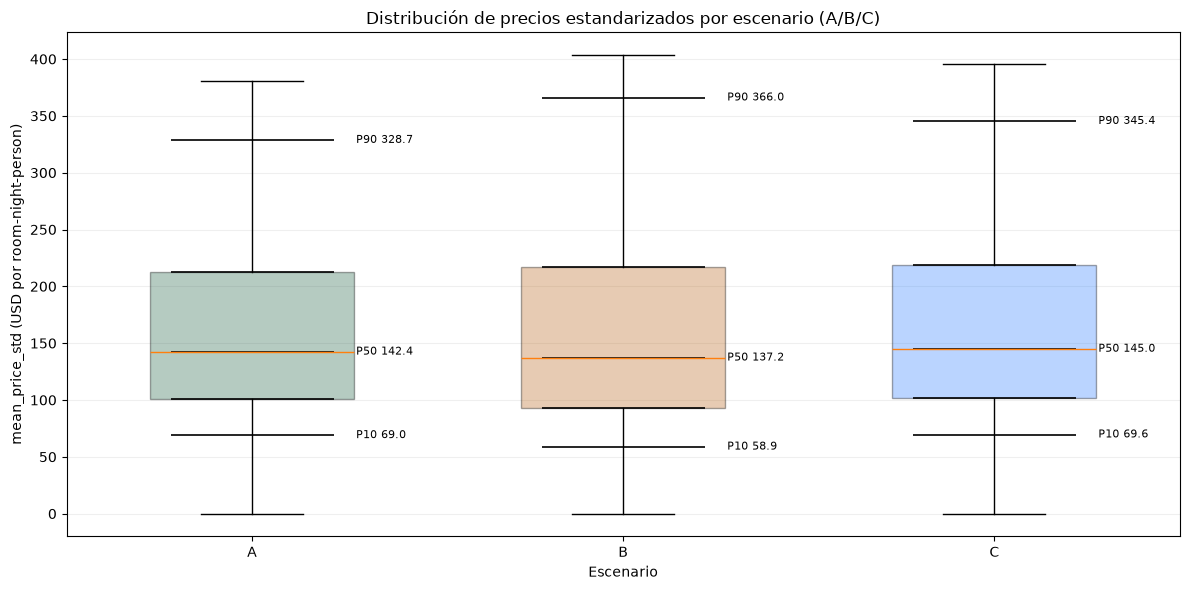

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Validación mínima de prerequisitos generados en celdas previas
required = {"A": A, "B": B, "C": C, "b": b}
for name, frame in required.items():
    if frame is None or len(frame) == 0:
        raise ValueError(f"No hay datos para {name}. Ejecutar primero la celda de construcción de A/B/C.")

# ==============================
# 1) BOXPLOT + ZONAS PERCENTILES
# ==============================
scenario_frames = {
    "A": A.copy(),
    "B": B.copy(),
    "C": C.copy(),
}

labels = ["A", "B", "C"]
box_data = []
percentiles = {}

for label in labels:
    values = scenario_frames[label]["mean_price_std"].dropna().values
    box_data.append(values)
    percentiles[label] = np.percentile(values, [10, 25, 50, 75, 90])

fig, ax = plt.subplots(figsize=(12, 6))

bp = ax.boxplot(
    box_data,
    tick_labels=labels,
    patch_artist=True,
    showfliers=False,
    widths=0.55,
)

palette = {"A": "#2D6A4F", "B": "#BC6C25", "C": "#3A86FF"}
for patch, label in zip(bp["boxes"], labels):
    patch.set_facecolor(palette[label])
    patch.set_alpha(0.35)

for i, label in enumerate(labels, start=1):
    p10, p25, p50, p75, p90 = percentiles[label]

    # Percentiles sobre cada caja para visualizar zonas de precio
    ax.hlines([p10, p25, p50, p75, p90], i - 0.22, i + 0.22, colors="black", linewidth=1.2)
    ax.text(i + 0.28, p10, f"P10 {p10:.1f}", fontsize=8, va="center")
    ax.text(i + 0.28, p50, f"P50 {p50:.1f}", fontsize=8, va="center")
    ax.text(i + 0.28, p90, f"P90 {p90:.1f}", fontsize=8, va="center")

ax.set_title("Distribución de precios estandarizados por escenario (A/B/C)")
ax.set_xlabel("Escenario")
ax.set_ylabel("mean_price_std (USD por room-night-person)")
ax.grid(alpha=0.2, axis="y")
plt.tight_layout()
plt.show()

## Conclusión

Con el fix de mapping aplicado en `apply_destination_mapping`, el pipeline productivo dejó de estar en 0,0% y pasó a **28,1% de match** (`de 4.726.040 a 16.797.297 noches extendidas`), recuperando una base geográfica usable para comparar contextos.

En la última ejecución completa del código quedaron **775.526 contextos** y **28.569 destinos** con baseline; la proporción de contextos de alta confianza se ubicó en torno a **22,8%**.

La matriz A/B/C confirma el trade-off observado desde TP1:
- A conserva más soporte por celda.
- B mejora homogeneidad, estabilidad y sensibilidad de detección.
- C agrega granularidad temporal, pero con mayor fragmentación.

Con evidencia cuantitativa y visual, concluímos a modo de cierre metodológico del TP2 emplear el **Escenario B** (`destination_final × month × price_bucket`) como baseline de referencia para TP3.